# Solar filament segmentation -- end-to-end pipeline

IEEE BigData Cup 2026, *Solar Filament Segmentation Challenge* (MAGFiLO, GONG H-alpha).

This notebook reproduces our submission **without re-training**: it loads the network
weights and the post-processing configuration stored in `weights/`, predicts every test
image, and writes `submission.csv` in the competition format.

![pipeline](../docs/figures/pipeline.png)

| stage | input | output | code |
|---|---|---|---|
| 1. pre-processing | 2048 x 2048 grey JPEG | resized, normalised image | `filseg.model.predict_images` |
| 2. segmentation network(s) | image | per-pixel filament probability (consensus of annotators) | `filseg.model` |
| 3. ensembling + TTA | probabilities of each model / flip | mean probability, 2048 x 2048 | `filseg.infer.predict_full` |
| 4. instance extraction | probability map | candidate components -> learned filter -> outlines at p > 0.5 | `filseg.postprocess.instances_from_prob` |
| 5. encoding | instances | COCO RLE rows of `submission.csv` | `filseg.submission` |


## 1. Setup

Set `DATA_DIR` to the unzipped competition data (`MAGFiLO_1.0_Kaggle_2026`; found automatically next to the repository or under `/kaggle/input`). Install the pinned packages with `pip install -r requirements.txt` if needed.

`PROFILE = "full"` reproduces the submission with all ten networks; `"fast"` uses the five EfficientNetV2-S networks with their own post-processing (about half the inference time, slightly lower out-of-fold PQ; see the table in section 2).

In [1]:
import json, os, sys, time
from pathlib import Path

PROFILE = os.environ.get("FILSEG_PROFILE", "full")      # "full" (submission) or "fast"
LIMIT = int(os.environ.get("FILSEG_LIMIT_TEST", "0"))    # > 0: only the first LIMIT test images (quick check)
SAVE_PROBS = os.environ.get("FILSEG_SAVE_PROBS")         # optional: also save the ensemble probability maps (.npz)

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO))

CANDIDATES = [REPO / "MAGFiLO_1.0_Kaggle_2026", REPO.parent / "MAGFiLO_1.0_Kaggle_2026"]
DATA_DIR = next((p for p in CANDIDATES if (p / "test" / "test_images").exists()), None)
if DATA_DIR is None:  # $FILSEG_DATA or the competition data mounted under /kaggle/input
    from filseg.train import find_data_dir
    DATA_DIR = find_data_dir(None)
WEIGHTS_DIR = Path(os.environ.get("FILSEG_WEIGHTS", REPO / "weights"))
OUT_CSV = REPO / ("submission.csv" if PROFILE == "full" else f"submission_{PROFILE}.csv")
print("repo:", REPO)
print("data:", DATA_DIR, "| exists:", DATA_DIR.exists())
print("profile:", PROFILE, "| test images:", LIMIT or "all")

repo: /tmp/repo_full
data: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026 | exists: True
profile: full | test images: all


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from filseg import data, infer, postprocess, submission
from filseg.postprocess import PostConfig

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

torch 2.11.0+cu130 | device: cuda


## 2. Trained models and post-processing configuration

| profile | networks | out-of-fold PQ (nested CV, 707 images) | T4 GPU time per image |
|---|---|---|---|
| `full` | 5 x U-Net ResNet34 + 5 x U-Net EfficientNetV2-S (one per CV fold) | 0.447 | ~12.8 s networks + ~0.5 s post-processing |
| `fast` | 5 x U-Net EfficientNetV2-S | 0.444 | ~7.1 s + ~0.5 s |

Post-processing: threshold, connected components, a learned component filter (gradient-boosted
trees on per-component features, stored as JSON in the manifest) and redrawing of each kept
instance at probability 0.5.

In [3]:
manifest = json.loads((WEIGHTS_DIR / "manifest.json").read_text())
if PROFILE == "fast":
    entries = [m for m in manifest["models"] if m["file"] in manifest["fast"]["models"]]
    post = manifest["fast"]["post"]
else:
    entries, post = manifest["models"], manifest["post"]
cfg = PostConfig(**post)
weight_files = [WEIGHTS_DIR / m["file"] for m in entries]
models = infer.load_models(weight_files, device)
pd.DataFrame(entries)[["file", "encoder", "res", "norm", "fold"]]

,file,encoder,res,norm,fold
0,unet_resnet34_2048_fold0.pt,resnet34,2048,disk,0
1,unet_resnet34_2048_fold1.pt,resnet34,2048,disk,1
2,unet_resnet34_2048_fold2.pt,resnet34,2048,disk,2
3,unet_resnet34_2048_fold3.pt,resnet34,2048,disk,3
4,unet_resnet34_2048_fold4.pt,resnet34,2048,disk,4
5,unet_tu-tf_efficientnetv2_s_2048_fold0.pt,tu-tf_efficientnetv2_s,2048,disk,0
6,unet_tu-tf_efficientnetv2_s_2048_fold1.pt,tu-tf_efficientnetv2_s,2048,disk,1
7,unet_tu-tf_efficientnetv2_s_2048_fold2.pt,tu-tf_efficientnetv2_s,2048,disk,2
8,unet_tu-tf_efficientnetv2_s_2048_fold3.pt,tu-tf_efficientnetv2_s,2048,disk,3
9,unet_tu-tf_efficientnetv2_s_2048_fold4.pt,tu-tf_efficientnetv2_s,2048,disk,4


In [4]:
summary = {k: v for k, v in post.items() if k != "scorer"}
if post.get("scorer"):
    summary["scorer"] = f"{len(post['scorer']['trees'])} trees on {post['scorer']['features']}"
summary

{'threshold': 0.25,
 'close_radius': 0,
 'fill_holes': True,
 'min_area': 0,
 'min_mean_prob': 0.0,
 'min_max_prob': 0.0,
 'merge_distance': 0,
 'dilate_radius': 0,
 'mask_threshold': 0.5,
 'min_score': 0.27999999999999997,
 'scorer': "200 trees on ['log_area', 'mean_prob', 'max_prob', 'p90_prob', 'std_prob', 'elongation', 'fill_ratio', 'radius', 'n_comp_image', 'area_rank', 'length', 'width']"}

## 3. Inference on the test images -> `submission.csv`

In [5]:
test_files = sorted((DATA_DIR / "test" / "test_images").glob("*.jp*g"))
if LIMIT:
    test_files = test_files[:LIMIT]
timing = {}
t0 = time.time()
df = infer.make_submission(models, DATA_DIR, cfg, device, tta=manifest.get("tta", 4), timing=timing, limit=LIMIT,
                           save_probs=Path(SAVE_PROBS) if SAVE_PROBS else None)
elapsed = time.time() - t0
df, report = submission.write(list(df.itertuples(index=False, name=None)), OUT_CSV, {f.stem for f in test_files})
print(f"{len(test_files)} images, {len(df)} filaments -> {OUT_CSV}")
print(f"end-to-end {elapsed / len(test_files):.2f} s per image on {device}: networks "
      f"{timing['network_s_per_image']:.2f} s + post-processing {timing['post_s_per_image']:.2f} s "
      f"({len(models)} models, TTA x{manifest.get('tta', 4)})")
print(report)
df.head()

180 images, 1076 filaments -> /tmp/repo_full/submission.csv
end-to-end 7.95 s per image on cuda: networks 7.40 s + post-processing 0.53 s (10 models, TTA x4)
{'rows': 1076, 'images': 177, 'test_images_without_prediction': 3, 'filaments_per_image': 6.08, 'area_p10_p50_p90': [523, 1389, 4597], 'problems': []}


,filament_id,segmentation_rle
0,20110120105534Ch_1,m_Zi23mo1101fPNMdn13[QNOdn12ZQNOfn12YQNNin10WQ...
1,20110130110334Ch_1,c_nd28fo14M3M2O6J0101OnPN]Ogn1b0VQNAjn1k00O1O1...
2,20110214175414Mh_1,\]b[22jo16L3M2O2M3I6O2O001oNWOhRNj0Vm1YOiRNh0U...
3,20110214175414Mh_2,_^^d22mo13N001O0O101O000010O01O1O0000000O010O1...
4,20110214175414Mh_3,fY_g28go1>B3N1N1O1O1O000OL4O2O10O1O1O100000001...


## 4. Visual check of the predicted filaments

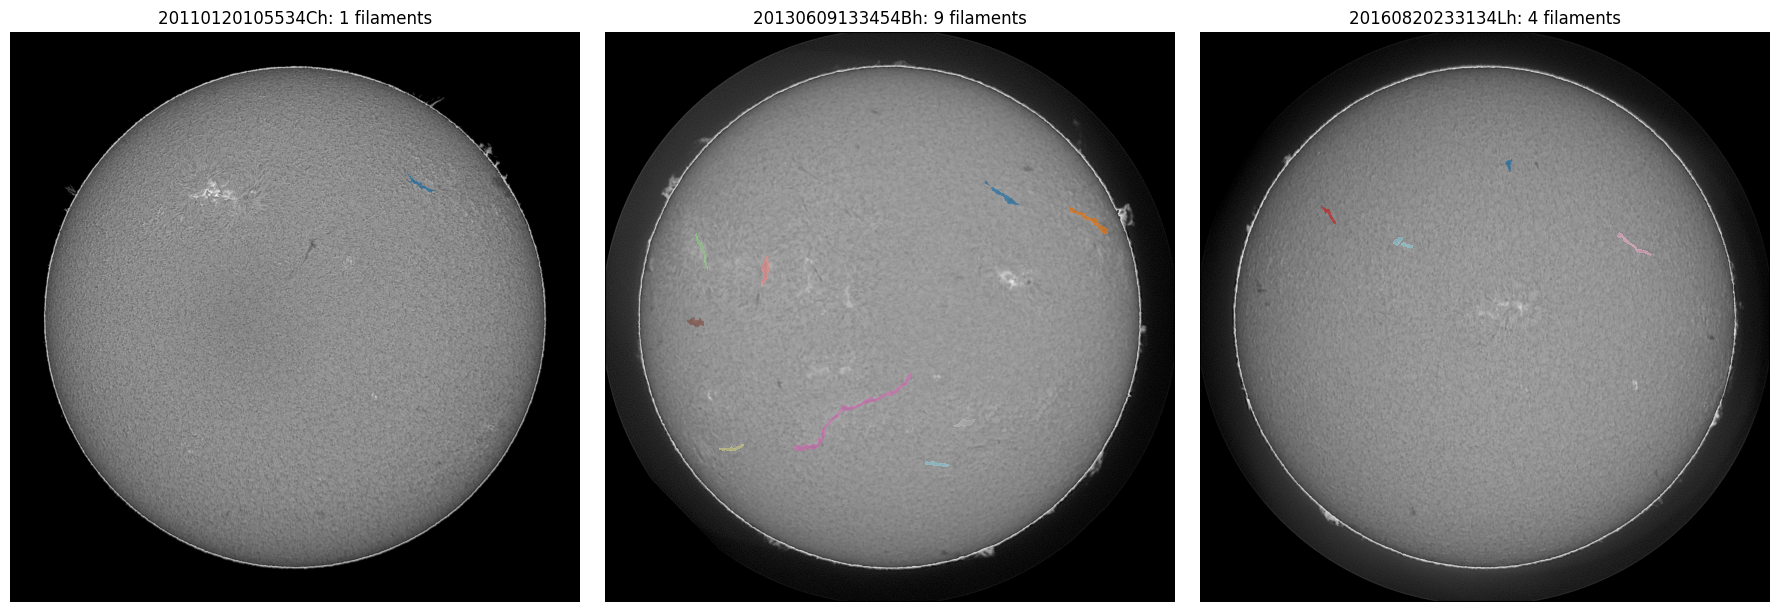

In [6]:
from filseg import rle
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, f in zip(axes, test_files[:: max(len(test_files) // 3, 1)]):
    img = data.read_image(f)
    rows = df[df["filament_id"].str.rsplit("_", n=1).str[0] == f.stem]
    lab = np.zeros(img.shape, np.int32)
    for k, counts in enumerate(rows["segmentation_rle"], start=1):
        lab[rle.decode(counts)] = k
    ax.imshow(img, cmap="gray")
    ax.imshow(np.ma.masked_equal(lab, 0), cmap="tab20", alpha=0.6, interpolation="nearest")
    ax.set_title(f"{f.stem}: {len(rows)} filaments")
    ax.axis("off")
plt.tight_layout()

## 5. Out-of-fold evaluation

The organisers' self-evaluation quantities (Panoptic Quality, IoU / Dice distributions,
one-to-many and many-to-one relations) on all 707 training images, each predicted only by
the models that did not see it during training, every annotator scored separately.
The figure and numbers below were produced by `scripts/make_figures.py evaluation` from the
saved out-of-fold probability maps; set `RUN_VALIDATION = True` to recompute them here from
the weights (about 15-30 min on one T4 GPU).

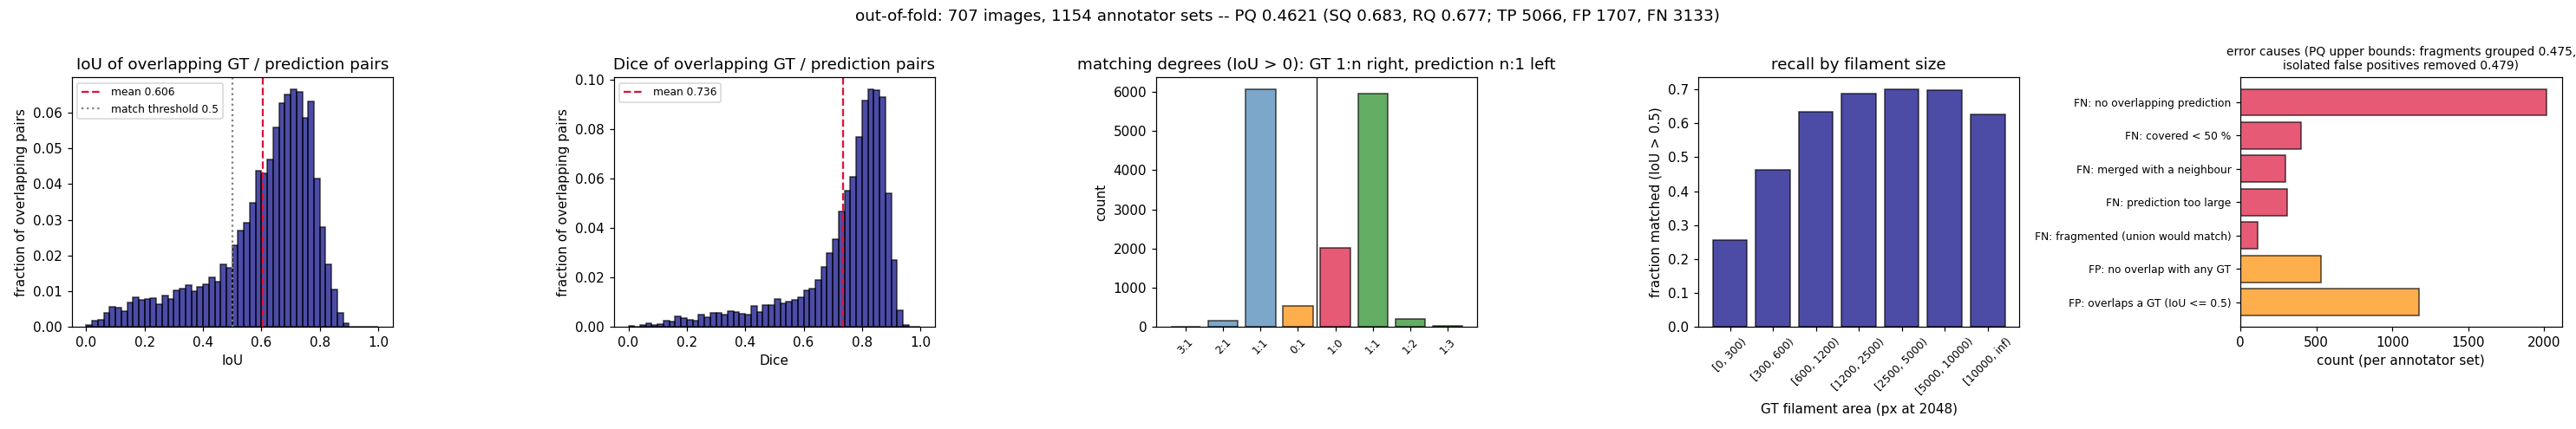

{
 "images": 707,
 "entries": 1154,
 "post": {
  "threshold": 0.25,
  "close_radius": 0,
  "fill_holes": true,
  "min_area": 0,
  "min_mean_prob": 0.0,
  "min_max_prob": 0.0,
  "merge_distance": 0,
  "dilate_radius": 0,
  "mask_threshold": 0.5,
  "scorer": {
   "trees": 200,
   "features": [
    "log_area",
    "mean_prob",
    "max_prob",
    "p90_prob",
    "std_prob",
    "elongation",
    "fill_ratio",
    "radius",
    "n_comp_image",
    "area_rank",
    "length",
    "width"
   ]
  },
  "min_score": 0.27999999999999997
 },
 "pq": 0.46210264779812443,
 "sq": 0.6828465103467745,
 "rq": 0.6767298958055036,
 "tp": 5066,
 "fp": 1707,
 "fn": 3133,
 "mean_iou_overlapping": 0.6056387424468994,
 "mean_dice_overlapping": 0.7362654805183411,
 "gt_degrees": {
  "0": 2016,
  "1": 5954,
  "2": 210,
  "3": 19
 },
 "pred_degrees": {
  "0": 531,
  "1": 6062,
  "2": 168,
  "3": 11
 },
 "recall_by_size": {
  "[0.0, 300.0)": 0.2567,
  "[300.0, 600.0)": 0.4626,
  "[600.0, 1200.0)": 0.6347,
  "[1200.

In [7]:
from IPython.display import Image, display

eval_png, eval_json = REPO / "docs" / "figures" / "evaluation.png", REPO / "docs" / "evaluation.json"
if eval_png.exists():
    display(Image(filename=str(eval_png)))
if eval_json.exists():
    print(json.dumps(json.loads(eval_json.read_text()), indent=1)[:3000])

In [8]:
from filseg import analysis, metrics
from filseg.metrics import Crop

RUN_VALIDATION = False  # set to True to recompute the out-of-fold evaluation from the weights
train_json = DATA_DIR / "train" / data.TRAIN_JSON
if RUN_VALIDATION and train_json.exists() and all("fold" in m for m in entries):
    groups = data.group_by_image(data.load_entries(train_json))
    folds = data.image_folds(list(groups), manifest.get("nfolds", 5), manifest.get("seed", 2026))
    preds, gt = {}, {}
    for k in sorted({m["fold"] for m in entries}):
        fold_models = [mm for mm, meta in zip(models, entries) if meta["fold"] == k]
        ids = [i for i in groups if folds[i] == k]
        images = [data.read_image(DATA_DIR / "train" / "train_images" / groups[i][0].file_name) for i in ids]
        for i, p in zip(ids, infer.predict_full(fold_models, images, device, tta=manifest.get("tta", 4))):
            lab, _ = postprocess.instances_from_prob(p, cfg)
            preds[i] = postprocess.label_to_crops(lab)
            for e in groups[i]:
                gt[e.entry_id] = [Crop.from_full(m) for m in e.masks()]
    res, overlap_df = metrics.evaluate(gt, preds)
    print("out-of-fold:", res)
    iou, dice = analysis.overlap_distributions(overlap_df)
    gdeg, pdeg = metrics.matching_degrees(overlap_df)
    print(f"mean IoU / Dice of overlapping pairs: {iou.mean():.3f} / {dice.mean():.3f}")
    print("GT -> number of overlapping predictions:", dict(sorted(gdeg.items())))
    print("prediction -> number of overlapping GT:", dict(sorted(pdeg.items())))

## 6. Re-training (reference only)

Each model in `weights/` was produced by `python -m filseg.train` with the arguments stored
in `weights/manifest.json` (field `train_args`). Training is not needed to reproduce the
submission.

In [9]:
pd.DataFrame([{"file": m["file"], "command": "python -m filseg.train " + m.get("train_args", "")} for m in manifest["models"]])

,file,command
0,unet_resnet34_2048_fold0.pt,python -m filseg.train --res 2048 --crop 768 -...
1,unet_resnet34_2048_fold1.pt,python -m filseg.train --res 2048 --crop 768 -...
2,unet_resnet34_2048_fold2.pt,python -m filseg.train --res 2048 --crop 768 -...
3,unet_resnet34_2048_fold3.pt,python -m filseg.train --res 2048 --crop 768 -...
4,unet_resnet34_2048_fold4.pt,python -m filseg.train --res 2048 --crop 768 -...
5,unet_tu-tf_efficientnetv2_s_2048_fold0.pt,python -m filseg.train --res 2048 --crop 768 -...
6,unet_tu-tf_efficientnetv2_s_2048_fold1.pt,python -m filseg.train --res 2048 --crop 768 -...
7,unet_tu-tf_efficientnetv2_s_2048_fold2.pt,python -m filseg.train --res 2048 --crop 768 -...
8,unet_tu-tf_efficientnetv2_s_2048_fold3.pt,python -m filseg.train --res 2048 --crop 768 -...
9,unet_tu-tf_efficientnetv2_s_2048_fold4.pt,python -m filseg.train --res 2048 --crop 768 -...
